In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [61]:
df = pd.read_csv('mapdataall.csv')
df2 = df[['incident_latitude', 'incident_longitude', 'incident_date_created']]
df2.dropna(inplace = True)
df2['incident_date_created'] = pd.to_datetime(df2['incident_date_created'])
df2['Year'] = df2['incident_date_created'].dt.year
df2['Month'] = df2['incident_date_created'].dt.month_name()
df2['Day'] = df2['incident_date_created'].dt.day_name()
df2['Time'] = df2['incident_date_created'].dt.hour
df2['incident_date_created'] = df2['incident_date_created'].dt.date
df2

C:\Users\noaha\AppData\Local\Temp\ipykernel_18400\2068322806.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2.dropna(inplace = True)
C:\Users\noaha\AppData\Local\Temp\ipykernel_18400\2068322806.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['incident_date_created'] = pd.to_datetime(df2['incident_date_created'])
C:\Users\noaha\AppData\Local\Temp\ipykernel_18400\2068322806.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the d

,incident_latitude,incident_longitude,incident_date_created,Year,Month,Day,Time
0,40.774000,-122.309000,2017-10-31,2017,October,Tuesday,11
1,1.000000,1.000000,2009-05-24,2009,May,Sunday,14
2,36.602575,-118.016510,2013-02-24,2013,February,Sunday,8
3,34.288877,-116.941311,2013-04-20,2013,April,Saturday,17
4,37.116295,-119.635004,2013-04-30,2013,April,Tuesday,12
...,...,...,...,...,...,...,...
3351,37.357481,-119.870253,2025-10-21,2025,October,Tuesday,12
3352,35.909937,-118.765302,2025-10-22,2025,October,Wednesday,10
3353,37.734211,-121.620807,2025-10-26,2025,October,Sunday,15
3354,40.001361,-122.275786,2025-10-27,2025,October,Monday,13


In [5]:
df3 = df2[df2['Year'] > 2020]
for i in df3['Year']:
    if i == 2021:
        df4 = df3[df3['Month'] > 'March']

df4.reset_index(inplace=True, drop=True)
df4['fire_started?'] = True
start_date = df4['incident_date_created'].iloc[0]
end_date = df4['incident_date_created'].iloc[-1]
dates = pd.date_range(start = start_date, end = end_date, freq='D')
dates = dates.date

existing = df4['incident_date_created'].dropna().tolist()
for d in dates:
    if d not in existing:
        idx = len(df4)
        df4.loc[idx, 'incident_date_created'] = d
        df4.loc[idx, 'incident_latitude']  = round(np.random.uniform(34, 40), 6)
        df4.loc[idx, 'incident_longitude'] = round(np.random.uniform(-124, -116), 6)
        df4.loc[idx, 'fire_started?'] = False
        existing.append(d)

df4 = df4.sort_values('incident_date_created').reset_index(drop=True)
df5 = df4.drop(columns = ['Year', 'Month', 'Day', 'Time'])
df5



C:\Users\noaha\AppData\Local\Temp\ipykernel_13160\1519176288.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df4['fire_started?'] = True
C:\Users\noaha\AppData\Local\Temp\ipykernel_13160\1519176288.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df4.loc[idx, 'incident_date_created'] = d


,incident_latitude,incident_longitude,incident_date_created,fire_started?
0,38.773294,-121.034998,2021-05-01,True
1,32.987532,-116.443391,2021-05-02,True
2,37.972349,-116.302586,2021-05-03,False
3,33.532246,-116.767011,2021-05-04,True
4,33.869720,-117.044072,2021-05-05,True
...,...,...,...,...
1888,37.264217,-122.338040,2025-10-25,False
1889,37.734211,-121.620807,2025-10-26,True
1890,40.001361,-122.275786,2025-10-27,True
1891,37.442685,-118.043633,2025-10-28,False


In [6]:
import openmeteo_requests
import requests_cache

In [7]:
cache_session = requests_cache.CachedSession('.cache', expire_after=3600)
openmeteo = openmeteo_requests.Client(session=cache_session)

In [8]:

cols = [
    "Elevation", "temperature_2m_max", "temperature_2m_min", "daylight_duration",
    "sunshine_duration", "uv_index_max", "precipitation_sum", "precipitation_hours",
    "wind_speed_10m_max", "wind_gusts_10m_max", "et0_fao_evapotranspiration",
    "cloud_cover_mean", "relative_humidity_2m_max", "relative_humidity_2m_min",
    "surface_pressure_max", "surface_pressure_min"
]

out = {c: [] for c in cols}

for i, (lat, lon, date) in enumerate(zip(df5['incident_latitude'],
                                         df5['incident_longitude'],
                                         df5['incident_date_created']), start=1):
    try:
        url = "https://historical-forecast-api.open-meteo.com/v1/forecast"
        params = {
            "latitude": float(lat),
            "longitude": float(lon),
            "start_date": str(date),
            "end_date": str(date),
            "daily": [
                "temperature_2m_max", "temperature_2m_min", "daylight_duration", "sunshine_duration",
                "uv_index_max", "precipitation_sum", "precipitation_hours", "wind_speed_10m_max",
                "wind_gusts_10m_max", "et0_fao_evapotranspiration", "cloud_cover_mean",
                "relative_humidity_2m_max", "relative_humidity_2m_min",
                "surface_pressure_max", "surface_pressure_min"
            ],
            "models": "best_match",
            "timezone": "UTC",
            "wind_speed_unit": "mph",
            "temperature_unit": "fahrenheit",
            "precipitation_unit": "inch",
        }
        responses = openmeteo.weather_api(url, params=params)
        response = responses[0]
        daily = response.Daily()

        def get_var(idx):
            try:
                arr = list(daily.Variables(idx).ValuesAsNumpy())
                return None if len(arr) == 0 else arr[0]
            except Exception:
                return None

        out["Elevation"].append(response.Elevation())
        out["temperature_2m_max"].append(get_var(0))
        out["temperature_2m_min"].append(get_var(1))
        out["daylight_duration"].append(get_var(2))
        out["sunshine_duration"].append(get_var(3))
        out["uv_index_max"].append(get_var(4))
        out["precipitation_sum"].append(get_var(5))
        out["precipitation_hours"].append(get_var(6))
        out["wind_speed_10m_max"].append(get_var(7))
        out["wind_gusts_10m_max"].append(get_var(8))
        out["et0_fao_evapotranspiration"].append(get_var(9))
        out["cloud_cover_mean"].append(get_var(10))
        out["relative_humidity_2m_max"].append(get_var(11))
        out["relative_humidity_2m_min"].append(get_var(12))
        out["surface_pressure_max"].append(get_var(13))
        out["surface_pressure_min"].append(get_var(14))

    except Exception as exc:
        # on error, append Nones so lengths stay aligned and continue
        for c in cols:
            out[c].append(None)
        print(f"Row {i} error:", exc)


# assign the collected lists as columns (lengths match df4 rows)
for c in cols:
    df5[c] = out[c]

final_df = df5

In [9]:
final_df.dropna(inplace=True)
final_df

,incident_latitude,incident_longitude,incident_date_created,fire_started?,Elevation,temperature_2m_max,temperature_2m_min,daylight_duration,sunshine_duration,uv_index_max,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,et0_fao_evapotranspiration,cloud_cover_mean,relative_humidity_2m_max,relative_humidity_2m_min,surface_pressure_max,surface_pressure_min
0,38.773294,-121.034998,2021-05-01,True,142.0,87.857597,49.247601,49805.976562,44803.945312,7.70,0.000000,0.0,8.815597,20.804100,0.244245,42.041668,72.0,16.0,999.063843,995.192505
1,32.987532,-116.443391,2021-05-02,True,634.0,81.365005,60.305000,48694.003906,34689.042969,8.70,0.000000,0.0,25.787672,47.424400,0.356950,31.000000,37.0,9.0,937.448364,931.041016
2,37.972349,-116.302586,2021-05-03,False,1810.0,65.043503,33.723499,49877.472656,42414.964844,8.50,0.000000,0.0,23.492760,31.541700,0.233666,4.708333,48.0,9.0,821.742920,813.922485
3,33.532246,-116.767011,2021-05-04,True,1075.0,82.297394,52.777397,49010.101562,45562.843750,8.60,0.000000,0.0,14.085998,15.211600,0.277917,1.458333,47.0,11.0,897.754211,889.853882
4,33.869720,-117.044072,2021-05-05,True,452.0,93.328697,55.708702,49183.011719,45576.699219,8.25,0.000000,0.0,21.269154,27.515100,0.318660,10.416667,62.0,9.0,962.822632,958.668640
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1888,37.264217,-122.338040,2025-10-25,False,119.0,61.258099,54.508099,39140.558594,0.000000,2.20,0.047244,3.0,9.517114,16.553801,0.022222,99.166664,100.0,78.0,1004.245850,1002.113647
1889,37.734211,-121.620807,2025-10-26,True,184.0,69.161903,55.571899,38930.828125,25391.841797,3.35,0.000000,0.0,19.422003,28.857300,0.092696,63.333332,90.0,49.0,996.036316,994.260864
1890,40.001361,-122.275786,2025-10-27,True,105.0,66.575302,46.235298,38394.273438,28767.136719,4.40,0.251969,4.0,16.790916,30.199499,0.091072,34.291668,99.0,31.0,1010.395874,1001.460266
1891,37.442685,-118.043633,2025-10-28,False,2508.0,55.030998,38.021000,38715.902344,35558.898438,5.25,0.000000,0.0,16.343884,24.383299,0.151837,0.000000,37.0,13.0,761.034851,753.185669


In [10]:
final_df.to_csv('weather_data.csv')

In [111]:
counties = df['incident_county'].value_counts()

In [112]:
df['incident_date_created'].sort_values(ascending=True)

504     1969-12-31T16:00:00Z
1124    1969-12-31T16:00:00Z
1       2009-05-24T14:56:00Z
2       2013-02-24T08:16:00Z
3       2013-04-20T17:30:00Z
                ...         
3351    2025-10-21T12:24:43Z
3352    2025-10-22T10:54:00Z
3353    2025-10-26T15:14:24Z
3354    2025-10-27T13:09:29Z
3355    2025-10-29T14:17:51Z
Name: incident_date_created, Length: 3356, dtype: object

In [113]:
color = ['#C3DCD8', '#EFD1D4', '#FBE8ED', '#D8D9DA', '#C5BD96', '#93B0AC']

In [114]:
counties = pd.DataFrame(counties)
counties.reset_index(inplace = True)
top_counties = counties.head(10)

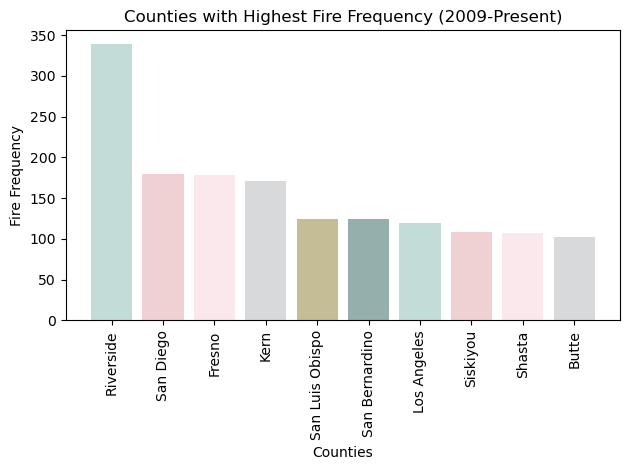

In [121]:
plt.bar(top_counties['incident_county'], top_counties['count'], color = color)
plt.xticks(rotation = 90)
plt.ylabel('Fire Frequency')
plt.xlabel('Counties')
plt.title('Counties with Highest Fire Frequency (2009-Present)')
plt.tight_layout()
plt.savefig('county_fires.svg')

In [116]:
df['month'] = pd.to_datetime(df['incident_date_created']).dt.month
month = df['month']
month = month.value_counts()
month_trend = pd.DataFrame(month).reset_index()
month_trend = month_trend.sort_values(by = 'month', ascending=True)
month_trend

,month,count
8,1,44
11,2,18
10,3,25
7,4,72
4,5,328
1,6,718
0,7,824
2,8,598
3,9,379
5,10,235


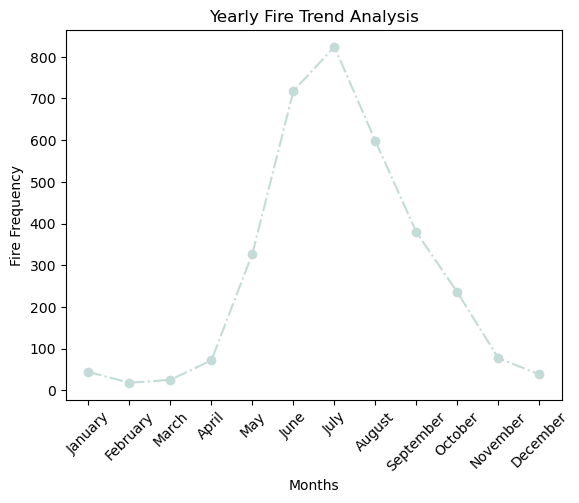

In [117]:
plt.plot(month_trend['month'], month_trend['count'], 'o-.', color = '#C3DCD8')
plt.xticks(ticks = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], labels = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December'], rotation = 45)
plt.xlabel('Months')
plt.ylabel('Fire Frequency')
plt.title('Yearly Fire Trend Analysis')
plt.savefig('yearly_trend.svg')

In [142]:
df['extinguish_time'] = (pd.to_datetime(df['incident_dateonly_extinguished']) - pd.to_datetime(df['incident_dateonly_created'])).dt.total_seconds() / 86400
days = df['extinguish_time'].dropna()
x = np.ceil(days)
x.sort_values()
value = []
for i in x:
    if i > 0 and i < 800:
       value.append(i)

sorted(value, reverse = True)

[392.0,
 375.0,
 374.0,
 366.0,
 365.0,
 360.0,
 358.0,
 336.0,
 330.0,
 319.0,
 314.0,
 282.0,
 282.0,
 281.0,
 281.0,
 272.0,
 271.0,
 269.0,
 267.0,
 266.0,
 264.0,
 264.0,
 263.0,
 260.0,
 259.0,
 256.0,
 256.0,
 255.0,
 254.0,
 254.0,
 254.0,
 254.0,
 253.0,
 253.0,
 252.0,
 251.0,
 247.0,
 247.0,
 245.0,
 245.0,
 245.0,
 244.0,
 244.0,
 242.0,
 242.0,
 240.0,
 240.0,
 240.0,
 240.0,
 240.0,
 239.0,
 239.0,
 239.0,
 238.0,
 237.0,
 237.0,
 236.0,
 236.0,
 236.0,
 236.0,
 235.0,
 235.0,
 235.0,
 235.0,
 234.0,
 234.0,
 234.0,
 234.0,
 233.0,
 232.0,
 232.0,
 232.0,
 231.0,
 231.0,
 231.0,
 230.0,
 230.0,
 229.0,
 229.0,
 229.0,
 228.0,
 227.0,
 226.0,
 226.0,
 226.0,
 226.0,
 226.0,
 226.0,
 225.0,
 225.0,
 225.0,
 223.0,
 223.0,
 222.0,
 222.0,
 222.0,
 221.0,
 221.0,
 221.0,
 220.0,
 220.0,
 220.0,
 220.0,
 220.0,
 219.0,
 219.0,
 219.0,
 219.0,
 219.0,
 218.0,
 218.0,
 217.0,
 217.0,
 217.0,
 217.0,
 217.0,
 216.0,
 216.0,
 216.0,
 216.0,
 216.0,
 216.0,
 215.0,
 215.0,
 215.0,


In [35]:
temp = pd.read_csv('weather_data.csv')
temp.set_index('Unnamed: 0', inplace = True)
temp = temp[['fire_started?', 'temperature_2m_max']].groupby('fire_started?').mean()
temp = temp.sort_values(by = 'temperature_2m_max', ascending=False)
temp = temp.reset_index()
temp

,fire_started?,temperature_2m_max
0,True,85.960383
1,False,67.869809


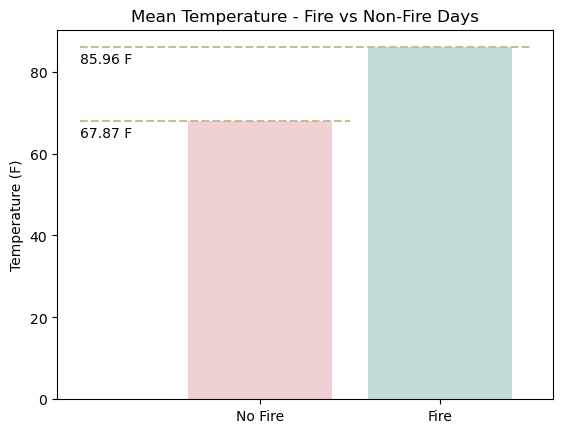

In [118]:
plt.bar(temp['fire_started?'], temp['temperature_2m_max'], color = ['#C3DCD8', '#EFD1D4'])
plt.plot([-1, 0, 1, 1.5], [85.96, 85.96, 85.96, 85.96], '--', color = '#C5BD96')
plt.plot([-1, 0, 0.5], [67.87, 67.87, 67.87], '--', color = '#C5BD96')
plt.text(-1, 82, '85.96 F')
plt.text(-1, 64, '67.87 F')
plt.xticks(ticks = [0, 1], labels = ['No Fire', 'Fire'])
plt.ylabel('Temperature (F)')
plt.title('Mean Temperature - Fire vs Non-Fire Days')
plt.savefig('temp_diff.svg')

In [83]:
acreage = df[['incident_name', 'incident_acres_burned', 'incident_dateonly_created', 'incident_dateonly_extinguished']].sort_values(by = 'incident_acres_burned', ascending=False).head().set_index('incident_name')
acreage['square_miles_burned'] = round(acreage['incident_acres_burned']*0.00156, 0)
acreage['date_started'] = acreage['incident_dateonly_created']
acreage['date_ended'] = acreage['incident_dateonly_extinguished']
acreage.drop(columns = ['incident_acres_burned', 'incident_dateonly_created', 'incident_dateonly_extinguished'], inplace = True)
sm = pd.DataFrame(acreage['square_miles_burned'])
sm.to_csv('square_mileage.csv')

In [104]:
df['Year'] = pd.to_datetime(df['incident_dateonly_created']).dt.year
grouped = df.groupby('Year')['incident_id'].count()
grouped.drop([1969, 2009], inplace = True)
grouped

Year
2013    141
2014     76
2015     99
2016    155
2017    429
2018    303
2019    263
2020    259
2021    186
2022    150
2023    133
2024    612
2025    547
Name: incident_id, dtype: int64

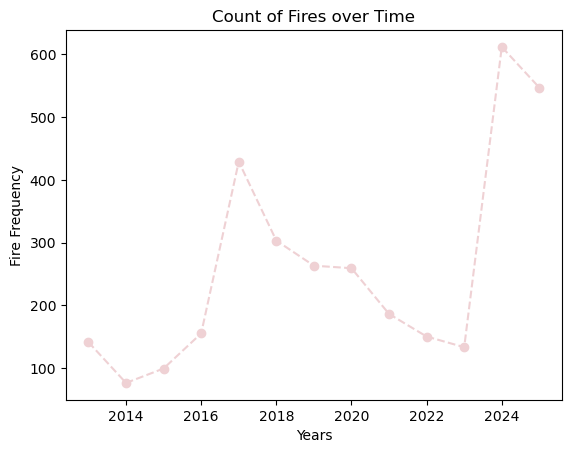

In [119]:
plt.plot(grouped, 'o--', color = '#EFD1D4')
plt.xlabel('Years')
plt.ylabel('Fire Frequency')
plt.title('Count of Fires over Time')
plt.savefig('yearly_fires.svg')

In [ ]:
#AI helped me with the open_meteo API and the process of getting the data from the API into the processed dataframe